# TIES merging

Trace trimming, sign election and disjoint averaging through a small merge.

Work with checkpoint differences relative to a common base. Keep the largest magnitudes in each task vector, elect the sign by the sum of retained values at each coordinate and average the entries agreeing with that sign. This example specifies a zero update for a tied vote.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

elected signs [ 1  1  0 -1 -1] merged [ 1.6   0.95  0.   -1.05 -1.9 ]


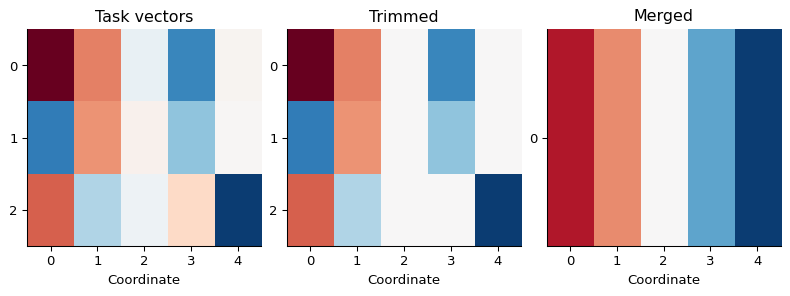

In [2]:
V = np.array(
    [[2.0, 1.0, -0.15, -1.3, 0.06], [-1.4, 0.9, 0.09, -0.8, 0.02], [1.2, -0.6, -0.1, 0.4, -1.9]]
)
k = 3
rank = np.argsort(-abs(V), axis=1, kind="stable")[:, :k]
trim = np.zeros_like(V)
np.put_along_axis(trim, rank, np.take_along_axis(V, rank, axis=1), axis=1)
sign = np.sign(trim.sum(0))
agree = (np.sign(trim) == sign) & (trim != 0) & (sign != 0)
out = np.divide(
    np.where(agree, trim, 0).sum(0),
    agree.sum(0),
    out=np.zeros(V.shape[1]),
    where=agree.sum(0) > 0,
)
print("elected signs", sign.astype(int), "merged", out.round(3))
assert np.allclose(out, [1.6, 0.95, 0, -1.05, -1.9])
fig, axes = plt.subplots(1, 3, figsize=(8.2, 3), constrained_layout=True)
for ax, arr, title in zip(axes, [V, trim, out[None, :]], ["Task vectors", "Trimmed", "Merged"]):
    ax.imshow(arr, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
    ax.set(title=title, xlabel="Coordinate", yticks=range(arr.shape[0]))
plt.show()

## Interpreting the result

A high-magnitude conflicting value can affect the election even when it is outvoted by count. The rule uses a signed sum.

## Exercise

Change the trimming fraction and report which coordinates switch sign.

## References

[Yadav et al., TIES-Merging (2023)](https://arxiv.org/abs/2306.01708)